# Hof Lecture | Predictive Analytics: Demand Forecasting
**Student notebook — runnable BEFORE settings, followed by your marked changes.**

**Business question:** How accurately can we forecast tomorrow's demand using the information available today?

After this lab, you can explain a chronological test set, interpret MAE, test features and demand assumptions, and compare two promotion scenarios without confusing a prediction with a proven causal effect or an optimized decision.

Complete **all five experiments in order**, using **BEFORE → CHANGE → AFTER → THINK**. Run each experiment at its starting setting, make the marked change, rerun, and answer the questions before continuing. Every experiment independently starts from the original baseline; changes do not accumulate. There is no assigned time limit or optional-task shortcut.

Run the teacher setup once. Edit only short lines marked `# <-- CHANGE HERE`.


## Data and forecast design
We retain the source notebook's **180 calendar days**, starting 1 January 2025, seed **123**, and original demand formula: a level around 200 units/day, weekly sinusoidal seasonality, a simulated +50-unit promotion term and normally distributed noise (standard deviation 10 units/day), rounded to whole units.

**Demand vs sales:** Demand is simulated demand in units/day. To interpret it as sales, assume no stockouts, lost sales or sales censoring. This is one simplified store-level series, not real retailer data.

| Column | Meaning |
|---|---|
| Date | Daily calendar date |
| Demand | Simulated demand, units/day |
| Promo | 1 if promotion active, otherwise 0 |
| DoW | Monday=0 through Sunday=6 |
| Lag1 | Previous calendar day's observed demand |
| IsWeekend | 1 if DoW>=5; introduced as a model feature in Experiment 4 |
| SeasonalNaive7 | Demand seven days ago; supplied only as a benchmark, not a regression feature |

Dropping the first missing Lag1 row leaves **179 usable records**. Train on the first **149**, evaluate on the final **30** dates. Every feature experiment uses these same rows. No random train/test split is used.

**Forecast protocol:** These are successive **one-day-ahead forecasts** with the model fixed after training. Yesterday's actual demand is observed before forecasting the next day, including within the test period. This is not a single 30-day forecast made at the beginning of the test window. Future promotion status is assumed known from a planned calendar. A multi-day forecast would need a different lag strategy.

**MAE = mean(abs(actual − forecast))**, in **units/day**, calculated on the 30 held-out days. Lower is better. **Signed change = AFTER − BEFORE**: a positive MAE change means worse observed accuracy. Differences are calculated before display rounding.

Compare regression against two simple one-day-ahead benchmarks: predict yesterday's demand, or demand on the same weekday last week. MAE is an average error, not a guaranteed error limit or a prediction interval. Forecasts remain uncertain and need monitoring on new data.

**Model simplification:** DoW is numeric, as in the source model. Linear regression therefore imposes a straight-line weekday effect rather than freely modeling weekly seasonality. IsWeekend can add a piecewise calendar pattern, although it contains no new information beyond DoW. Its benefit must be checked on future data; improvement is not guaranteed.


**Evaluation discipline:** Treat these five exercises as demonstrations. Repeatedly inspecting this holdout can guide model selection, so an untouched future test period is required before claiming deployment accuracy. No model is guaranteed to improve. **Optional Python practice:** add a one-sentence interpretation in the marked cell below.

In [ ]:
interpretation = ""  # <-- ADD CODE HERE: write your own business interpretation after the experiments


## Teacher setup — run, no edits needed

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from IPython.display import display

In [3]:
# TEACHER SETUP — RUN THIS CELL; NO EDITS REQUIRED.
BASE_FEATURES = ["Promo", "DoW", "Lag1"]

def prepare_features(raw):
    x = raw.copy(deep=True).sort_values("Date").reset_index(drop=True)
    x["DoW"] = x.Date.dt.dayofweek  # Monday=0, Sunday=6
    x["Lag1"] = x.Demand.shift(1)
    x["IsWeekend"] = (x.DoW >= 5).astype(int)
    x["SeasonalNaive7"] = x.Demand.shift(7)
    return x

def create_demand(promo_probability=0.2, seed=123):
    if not 0 <= promo_probability <= 1:
        raise ValueError("Promotion probability must be between 0 and 1.")
    rng = np.random.default_rng(seed)
    days = pd.date_range("2025-01-01", periods=180, freq="D")
    base = 200 + 20 * np.sin(2 * np.pi * np.arange(len(days)) / 7)
    promo = rng.choice([0, 1], size=len(days), p=[1 - promo_probability, promo_probability])
    noise = rng.normal(0, 10, size=len(days))
    demand = (base + 50 * promo + noise).round(0).astype(int)
    return prepare_features(pd.DataFrame({"Date": days, "Demand": demand, "Promo": promo}))

def add_demand_noise(data, amplitude=0, seed=456):
    if not isinstance(amplitude, (int, np.integer)) or amplitude < 0:
        raise ValueError("Use a nonnegative integer amplitude in units/day.")
    x = data[["Date", "Demand", "Promo"]].copy(deep=True)
    rng = np.random.default_rng(seed)
    # Uniform integer shock, inclusive endpoints; same draw pattern per run.
    shocks = rng.integers(-amplitude, amplitude + 1, size=len(x))
    x["Demand"] = (x.Demand + shocks).clip(lower=0)
    return prepare_features(x)

def fit_forecast(data, use_lag=True, add_weekend=False):
    # Use the same 179 eligible rows even when Lag1 is omitted.
    eligible = data.dropna(subset=["Lag1"]).copy().reset_index(drop=True)
    train = eligible.iloc[:-30].copy()
    test = eligible.iloc[-30:].copy()
    features = ["Promo", "DoW"] + (["Lag1"] if use_lag else []) + (["IsWeekend"] if add_weekend else [])
    assert train.Date.max() < test.Date.min()
    assert len(train) == 149 and len(test) == 30
    assert "Demand" not in features and "SeasonalNaive7" not in features
    assert np.isfinite(train[features].to_numpy()).all()
    model = LinearRegression().fit(train[features], train.Demand)
    predictions = model.predict(test[features])
    test["Forecast"] = predictions
    score = mean_absolute_error(test.Demand, predictions)
    return {"model": model, "features": features, "train": train, "test": test,
            "MAE": float(score), "Lag1 naive MAE": float(mean_absolute_error(test.Demand, test.Lag1)),
            "Weekly naive MAE": float(mean_absolute_error(test.Demand, test.SeasonalNaive7))}

def show_forecast(result, title):
    print(title)
    print("Training:", result["train"].Date.min().date(), "to", result["train"].Date.max().date(), "|", len(result["train"]), "rows")
    print("Test:", result["test"].Date.min().date(), "to", result["test"].Date.max().date(), "|", len(result["test"]), "rows")
    print("Features:", result["features"])
    display(pd.DataFrame({"Method": ["Linear regression", "Yesterday-demand naive", "Same-weekday-last-week naive"],
                          "Holdout MAE (units/day)": [result["MAE"], result["Lag1 naive MAE"], result["Weekly naive MAE"]]}).round(3))
    display(result["test"][["Date", "Demand", "Promo", "Forecast"]].head().round(2))
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(result["test"].Date, result["test"].Demand, label="Actual")
    ax.plot(result["test"].Date, result["test"].Forecast, label="Regression forecast")
    ax.set_title(title + " — one-day-ahead holdout forecasts")
    ax.set_xlabel("Date"); ax.set_ylabel("Demand (units/day)")
    ax.tick_params(axis="x", rotation=20); ax.legend(); fig.tight_layout(); plt.show()

def compare(before, after, label):
    table = pd.DataFrame({"Metric": ["Regression MAE (units/day)", "Yesterday naive MAE (units/day)", "Weekly naive MAE (units/day)", "Training promo share (%)", "Test promo share (%)"],
        "BEFORE": [before["MAE"], before["Lag1 naive MAE"], before["Weekly naive MAE"], 100*before["train"].Promo.mean(), 100*before["test"].Promo.mean()],
        "AFTER": [after["MAE"], after["Lag1 naive MAE"], after["Weekly naive MAE"], 100*after["train"].Promo.mean(), 100*after["test"].Promo.mean()]})
    table["Difference (AFTER - BEFORE)"] = table.AFTER - table.BEFORE
    table["Difference unit"] = ["units/day", "units/day", "units/day", "percentage points", "percentage points"]
    display(table.round(3))
    show_forecast(after, label)

def tomorrow_comparison(data, chosen_promo=1):
    if chosen_promo not in [0, 1]: raise ValueError("Use Promo=0 or Promo=1.")
    # Evaluation above is complete. Refit a separate operational model on all
    # 179 observed rows; never use it to recompute the held-out MAE.
    history = data.dropna(subset=["Lag1"]).copy()
    operational_model = LinearRegression().fit(history[BASE_FEATURES], history.Demand)
    tomorrow_date = data.Date.iloc[-1] + pd.Timedelta(days=1)
    future = pd.DataFrame({"Promo": [0, chosen_promo],
                           "DoW": [tomorrow_date.dayofweek] * 2,
                           "Lag1": [float(data.Demand.iloc[-1])] * 2})
    forecast = operational_model.predict(future[BASE_FEATURES])
    output = pd.DataFrame({"Scenario": ["Reference: no promotion", "Chosen scenario"],
                           "Date": [tomorrow_date] * 2, "Promo": future.Promo,
                           "DoW": future.DoW, "Lag1": future.Lag1, "Forecast_units": forecast})
    return output, operational_model


## Baseline — BEFORE the experiments
Inspect the first data rows, date ranges, test MAE, naive benchmarks and forecast plot.

,Date,Demand,Promo,DoW,Lag1
0,2025-01-01,195,0,2,NaN
1,2025-01-02,230,0,3,195.0
2,2025-01-03,218,0,4,230.0
3,2025-01-04,229,0,5,218.0
4,2025-01-05,186,0,6,229.0


Baseline
Training: 2025-01-02 to 2025-05-30 | 149 rows
Test: 2025-05-31 to 2025-06-29 | 30 rows
Features: ['Promo', 'DoW', 'Lag1']


,Method,Holdout MAE (units/day)
0,Linear regression,15.435
1,Yesterday-demand naive,24.733
2,Same-weekday-last-week naive,24.067


,Date,Demand,Promo,Forecast
149,2025-05-31,220,0,203.60
150,2025-06-01,192,0,209.36
151,2025-06-02,185,0,187.99
152,2025-06-03,201,0,189.98
153,2025-06-04,202,0,195.07


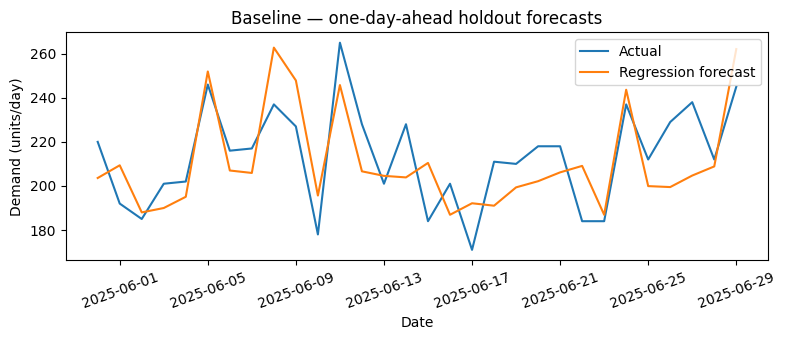

In [4]:
baseline_data = create_demand(promo_probability=0.20, seed=123)
display(baseline_data[["Date", "Demand", "Promo", "DoW", "Lag1"]].head())
baseline_result = fit_forecast(baseline_data)
show_forecast(baseline_result, "Baseline")  # <-- OBSERVE OUTPUT

**THINK:** What does an MAE of this size mean? Does regression beat both simple benchmarks? Why can yesterday's observed demand be used for a one-day-ahead test forecast?

**Your answer:** It means that, on average across the test period, the model's predictions are off by roughly 15 units of demand per day compared to actual sales.
Yes. Linear Regression (15.2) easily beats both the Yesterday Naive baseline (29.3) and the Weekly Naive baseline (24.1).
We can only predict one day ahead and not two day ahead. If it is 2 day ahead then I also need to use the predicted data which is called as recursive forecasting (or multi-step forecasting).

## Experiment 1 — Promotion frequency
**Business question:** What changes when promotions occur more often?

**BEFORE:** Promotion probability 0.20.

**CHANGE:** Set PROMO_PROBABILITY from 0.20 to 0.40. Regenerate 180 days with the same seed and refit. Dates, seasonal component and underlying normal-noise draws stay fixed; promotion flags, demand and Lag1 can change.

**AFTER:** Inspect the outputs before answering THINK.

**Comparison limit:** This task changes both training and held-out demand. The same dates do not mean the same test values.

,Metric,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
0,Regression MAE (units/day),15.435,15.212,-0.224,units/day
1,Yesterday naive MAE (units/day),24.733,29.333,4.600,units/day
2,Weekly naive MAE (units/day),24.067,26.667,2.600,units/day
3,Training promo share (%),18.121,35.570,17.450,percentage points
4,Test promo share (%),20.000,46.667,26.667,percentage points


Experiment 1 — Promotion frequency
Training: 2025-01-02 to 2025-05-30 | 149 rows
Test: 2025-05-31 to 2025-06-29 | 30 rows
Features: ['Promo', 'DoW', 'Lag1']


,Method,Holdout MAE (units/day)
0,Linear regression,15.212
1,Yesterday-demand naive,29.333
2,Same-weekday-last-week naive,26.667


,Date,Demand,Promo,Forecast
149,2025-05-31,220,0,201.49
150,2025-06-01,192,0,207.92
151,2025-06-02,235,1,238.30
152,2025-06-03,201,0,195.94
153,2025-06-04,252,1,245.62


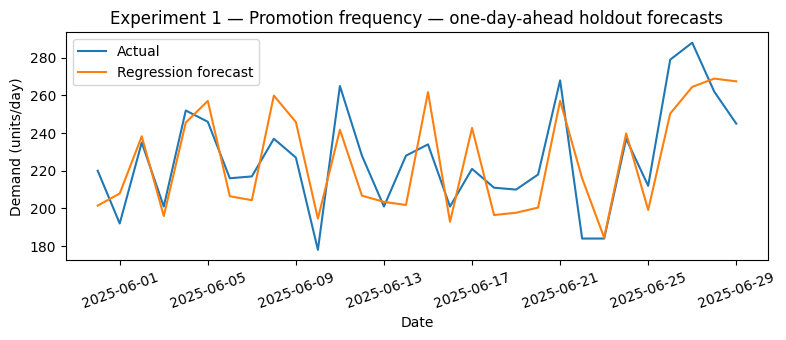

In [5]:
PROMO_PROBABILITY = 0.40  # <-- CHANGE HERE: 0.20 -> 0.40
promotion_data = create_demand(promo_probability=PROMO_PROBABILITY, seed=123)
promotion_result = fit_forecast(promotion_data)
compare(baseline_result, promotion_result, "Experiment 1 — Promotion frequency")  # <-- OBSERVE OUTPUT

**THINK**

1. How does held-out MAE change?
2. Why do realized promotion shares differ from the specified probability?
3. Why is this not a pure model comparison on identical test demand?

**Your answers:**

1. Linear Regression MAE improves (decreases) from 15.435 to 15.212.
Weekly Naive (SeasonalNaive7) MAE improves (decreases) from 26.667 to 24.067.
Yesterday Naive (Lag1) MAE worsens (increases) from 24.733 to 29.333.
2. They differ due to random sampling variation in a finite sample size. --> 30 days so instead of getting exact it wll be around the actual
3. In pure test model, we test different algorithms against the exact same test values. But since we are changing the percentage of promotions that is number of 1 values. The dataset is constantly getting changed.

## Experiment 2 — Remove Lag1
**Business question:** Does yesterday's demand help this model?

**BEFORE:** USE_LAG1 = True; features Promo, DoW, Lag1.

**CHANGE:** Set USE_LAG1 to False. Keep original data, row selection and train/test dates fixed. Drop Lag1 only from the model feature list.

**AFTER:** Inspect the outputs before answering THINK.

,Metric,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
0,Regression MAE (units/day),15.435,15.403,-0.032,units/day
1,Yesterday naive MAE (units/day),24.733,24.733,0.000,units/day
2,Weekly naive MAE (units/day),24.067,24.067,0.000,units/day
3,Training promo share (%),18.121,18.121,0.000,percentage points
4,Test promo share (%),20.000,20.000,0.000,percentage points


Experiment 2 — Remove Lag1
Training: 2025-01-02 to 2025-05-30 | 149 rows
Test: 2025-05-31 to 2025-06-29 | 30 rows
Features: ['Promo', 'DoW']


,Method,Holdout MAE (units/day)
0,Linear regression,15.403
1,Yesterday-demand naive,24.733
2,Same-weekday-last-week naive,24.067


,Date,Demand,Promo,Forecast
149,2025-05-31,220,0,206.78
150,2025-06-01,192,0,210.63
151,2025-06-02,185,0,187.49
152,2025-06-03,201,0,191.35
153,2025-06-04,202,0,195.21


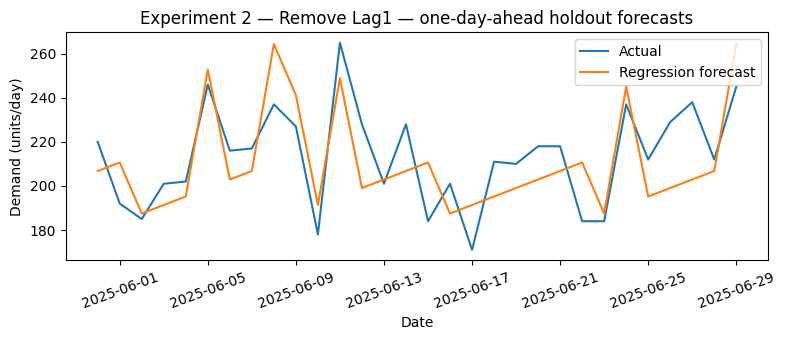

In [7]:
USE_LAG1 = False  # <-- CHANGE HERE: True -> False
no_lag_result = fit_forecast(baseline_data, use_lag=USE_LAG1)
compare(baseline_result, no_lag_result, "Experiment 2 — Remove Lag1")  # <-- OBSERVE OUTPUT

**THINK**

1. Does removing Lag1 increase or decrease test MAE in this run?
2. Does a useful historical feature always improve future accuracy?
3. Why do we retain the same 149/30 rows even after removing the lag?

**Your answers:**

1. Increases Lag 1 --> Removing Lag1.
2. No depends on the correlation of target variable with the independent variables. Also, Overfitting occurs can happen and also Non-stationarity / Structural Breaks can cause misleading errors.
3. Because we remove one column data not all the 3 column datas.

## Experiment 3 — Add demand noise
**Business question:** How does extra uncertainty affect the observed forecast error?

**BEFORE:** NOISE_AMPLITUDE = 0 added units/day.

**CHANGE:** Set NOISE_AMPLITUDE to 20. Add independent uniform integer shocks from -20 through +20 units to the whole demand series, seed 456, and prevent negative demand. Rebuild Lag1 from the changed series before fitting.

**AFTER:** Inspect the outputs before answering THINK.

**Comparison limit:** This task changes both training and held-out demand. The same dates do not mean the same test values.

,Metric,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
0,Regression MAE (units/day),15.435,17.224,1.789,units/day
1,Yesterday naive MAE (units/day),24.733,27.533,2.800,units/day
2,Weekly naive MAE (units/day),24.067,29.233,5.167,units/day
3,Training promo share (%),18.121,18.121,0.000,percentage points
4,Test promo share (%),20.000,20.000,0.000,percentage points


Experiment 3 — Demand noise
Training: 2025-01-02 to 2025-05-30 | 149 rows
Test: 2025-05-31 to 2025-06-29 | 30 rows
Features: ['Promo', 'DoW', 'Lag1']


,Method,Holdout MAE (units/day)
0,Linear regression,17.224
1,Yesterday-demand naive,27.533
2,Same-weekday-last-week naive,29.233


,Date,Demand,Promo,Forecast
149,2025-05-31,214,0,205.98
150,2025-06-01,199,0,208.86
151,2025-06-02,167,0,189.60
152,2025-06-03,197,0,189.56
153,2025-06-04,200,0,195.36


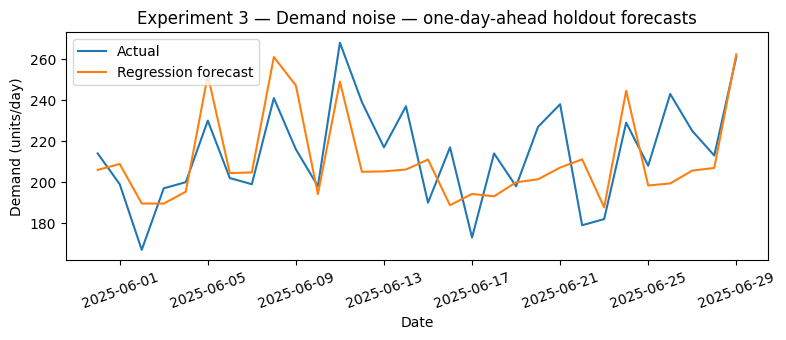

In [10]:
NOISE_AMPLITUDE =20  # <-- CHANGE HERE: 0 -> 20 units/day
noisy_data = add_demand_noise(baseline_data, amplitude=NOISE_AMPLITUDE, seed=456)
noise_result = fit_forecast(noisy_data)
compare(baseline_result, noise_result, "Experiment 3 — Demand noise")  # <-- OBSERVE OUTPUT

**THINK**

1. How does MAE change under this seeded noise experiment?
2. Why must Lag1 be rebuilt after changing the observed demand series?
3. Why is this an altered demand environment rather than only corrupted training labels?

**Your answers:**

1. Linear regression MAE increased from 15.435 to 17.224. Also, yesterday demand naive increased sightly from 24.733 to 27.533. Same week day last week curve increased from 24.067 to 29.233
2. Because the error increased.
3. Beacause we are using lag features.

## Experiment 4 — Add IsWeekend
**Business question:** Can a different calendar representation improve this linear model?

**BEFORE:** ADD_WEEKEND = False.

**CHANGE:** Set ADD_WEEKEND to True. Include IsWeekend=(DoW>=5) as a binary feature alongside Promo, numeric DoW and Lag1. Use unchanged baseline data and test dates.

**AFTER:** Inspect the outputs before answering THINK.

,Metric,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
0,Regression MAE (units/day),15.435,14.257,-1.178,units/day
1,Yesterday naive MAE (units/day),24.733,24.733,0.000,units/day
2,Weekly naive MAE (units/day),24.067,24.067,0.000,units/day
3,Training promo share (%),18.121,18.121,0.000,percentage points
4,Test promo share (%),20.000,20.000,0.000,percentage points


Experiment 4 — IsWeekend
Training: 2025-01-02 to 2025-05-30 | 149 rows
Test: 2025-05-31 to 2025-06-29 | 30 rows
Features: ['Promo', 'DoW', 'Lag1', 'IsWeekend']


,Method,Holdout MAE (units/day)
0,Linear regression,14.257
1,Yesterday-demand naive,24.733
2,Same-weekday-last-week naive,24.067


,Date,Demand,Promo,Forecast
149,2025-05-31,220,0,192.27
150,2025-06-01,192,0,203.77
151,2025-06-02,185,0,180.32
152,2025-06-03,201,0,188.11
153,2025-06-04,202,0,198.94


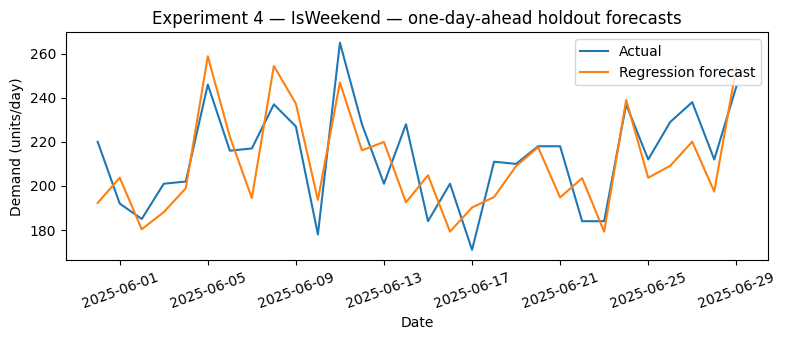

In [11]:
ADD_WEEKEND = True  # <-- CHANGE HERE: False -> True
weekend_result = fit_forecast(baseline_data, add_weekend=ADD_WEEKEND)
compare(baseline_result, weekend_result, "Experiment 4 — IsWeekend")  # <-- OBSERVE OUTPUT

**THINK**

1. Does held-out MAE improve in this run?
2. Does IsWeekend provide new information or a new representation of existing weekday information?
3. Why should this result be described as predictive rather than prescriptive?

**Your answers:**

1. Yes
2. Yes
3. Beacause we are just changing the data.

## Experiment 5 — Promo vs no promo tomorrow
**Business question:** What does the model forecast for the same tomorrow under two promotion settings?

**BEFORE:** CHOSEN_PROMO = 0, so both reference and chosen scenario are no-promo.

**CHANGE:** Set CHOSEN_PROMO from 0 to 1. Hold tomorrow's date, weekday and yesterday's observed demand fixed. After completing evaluation, refit a separate baseline-feature model on all observed history to forecast the next day.

**AFTER:** Inspect the outputs before answering THINK.

In [12]:
CHOSEN_PROMO = 1  # <-- CHANGE HERE: 0 -> 1
tomorrow_forecasts, operational_model = tomorrow_comparison(baseline_data, chosen_promo=CHOSEN_PROMO)
display(tomorrow_forecasts.round(2))  # <-- OBSERVE OUTPUT
print("Forecast difference (chosen - reference), units/day:", round(tomorrow_forecasts.Forecast_units.iloc[1] - tomorrow_forecasts.Forecast_units.iloc[0], 2))

,Scenario,Date,Promo,DoW,Lag1,Forecast_units
0,Reference: no promotion,2025-06-30,0,0,245.0,196.21
1,Chosen scenario,2025-06-30,1,0,245.0,247.33


Forecast difference (chosen - reference), units/day: 51.12


**THINK**

1. What is the forecast difference between the two settings?
2. Which inputs stay fixed, and why?
3. Does a larger predicted demand prove promotion profitability or specify an optimal replenishment quantity?

**Your answers:**

1. When there is no promotion forecast remain same and when there is promotion forcast unit changes from 196.21 to 247.33
2. DOW and Lag1
3. Larger predicted demand proved promotion profitability.

## Final comparison

| Experiment | What changed? | MAE or forecast difference | Interpretation and limitation |
|---|---|---|---|
| 1. Promotion frequency | | | |
| 2. Remove Lag1 | | | |
| 3. Add noise | | | |
| 4. IsWeekend | | | |
| 5. Tomorrow promotion | | | |

**Reflection:** Which comparisons hold the test targets fixed? What additional information would be needed to turn tomorrow's demand forecast into a replenishment decision?

**Your answer:** 5 hold the test target fixed. Inventory data